# 08 — Análisis de errores de la Base

Antes de sumar features nuevas, miro **dónde se equivoca** el modelo actual. Uso el mismo modelo fijo (`HistGradientBoostingClassifier`) y la misma CV que en `07_nuevas_features.ipynb`, con la **Base** = B+C+D+E + TF-IDF del título (500) + `VendedorEncoder` con target + `category_id` con `TargetEncoder` (el bloque K de la 07).

Para tener una predicción "honesta" de **cada** fila de train uso `cross_val_predict` (visto en `material/modelos de ensamble/S8_Ensambles.ipynb`): cada fila se predice con el modelo entrenado en los otros 4 folds, o sea, con un modelo que nunca la vio. A eso se le dice predicción *out-of-fold* (OOF).

Plan:
1. Reproducir la Base (≈ 0,9237) a partir de las predicciones OOF.
2. Accuracy por segmento (vendedor, tipo de publicación, modo de compra, moneda, precio, categoría).
3. ¿Los errores son "seguros" o "dudosos"? (distribución de la probabilidad predicha).
4. 60 errores para leer a mano.
5. Conclusión: qué parece ruido irreducible y qué podría capturar el modelo.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, TargetEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

from features import aplanar_anidadas, agregar_logs, CapeoPorMoneda, VendedorEncoder

SEED = 42

train = pd.read_json("../data/train_data.jsonlines", lines=True)
y = (train["condition"] == "new").astype(int)
train = aplanar_anidadas(train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelo_fijo = HistGradientBoostingClassifier(
    learning_rate=0.1, max_depth=None, max_iter=200, random_state=SEED
)

columnas_categoricas_base = ["listing_type_id", "buying_mode", "shipping_mode", "seller_state"]
columnas_numericas_base = [
    "log_price", "log_available_quantity", "automatic_relist",
    "sold_quantity", "initial_quantity",
    "n_fotos", "n_atributos", "n_variaciones", "tiene_video", "tiene_garantia",
    "free_shipping", "local_pick_up", "n_metodos_pago", "accepts_mercadopago",
    "es_tienda_oficial", "tiene_descuento", "tiene_oferta", "tiene_parent_item",
]

preprocesador_base = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas_base),
    ("num", "passthrough", columnas_numericas_base),
    ("tfidf", TfidfVectorizer(max_features=500), "title"),
    ("vendedor", VendedorEncoder(incluir_target=True), ["seller_id", "log_price"]),
    ("categoria", TargetEncoder(target_type="binary", random_state=SEED), ["category_id"]),
], sparse_threshold=0)

pipeline_base = Pipeline([
    ("capeo", CapeoPorMoneda(columnas=["price", "base_price"], columna_grupo="currency_id")),
    ("logs", FunctionTransformer(agregar_logs)),
    ("preprocesador", preprocesador_base),
    ("modelo", modelo_fijo),
])

## 1. Predicciones out-of-fold y chequeo de la Base

`cross_val_predict(..., method="predict_proba")` devuelve, para cada fila, la probabilidad de cada clase según el modelo del fold en el que esa fila quedó como validación. Me quedo con la columna 1 = P(`new`).

Para chequear que reproduzco la Base no vuelvo a correr `cross_validate`: como uso **el mismo `cv`** (mismos folds) y el modelo es determinístico (`random_state=42`), calculo accuracy y roc_auc fold por fold sobre las predicciones OOF, y eso da exactamente lo mismo que daría `cross_validate`. Si no da ≈ 0,9237, paro.

In [2]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    prob_new = cross_val_predict(pipeline_base, train, y, cv=cv, method="predict_proba")[:, 1]

pred_new = (prob_new >= 0.5).astype(int)

accuracy_folds, roc_auc_folds = [], []
for _, indices_validacion in cv.split(train, y):
    accuracy_folds.append(accuracy_score(y.iloc[indices_validacion], pred_new[indices_validacion]))
    roc_auc_folds.append(roc_auc_score(y.iloc[indices_validacion], prob_new[indices_validacion]))

print("Base -> accuracy:", round(np.mean(accuracy_folds), 4), "+/-", round(np.std(accuracy_folds), 4),
      "| roc_auc:", round(np.mean(roc_auc_folds), 4))
print("Errores totales:", (pred_new != y).sum(), "de", len(y))

Base -> accuracy: 0.9233 +/- 0.001 | roc_auc: 0.9783
Errores totales: 5370 de 70000


In [3]:
matriz = confusion_matrix(y, pred_new)
pd.DataFrame(matriz,
             index=["real used", "real new"],
             columns=["predicho used", "predicho new"])

,predicho used,predicho new
real used,30243,2169
real new,3201,34387


## 2. Accuracy por segmento

Armo una tabla `analisis` con, por fila: la clase real, la probabilidad OOF, la predicción, si es error, y las columnas de segmentación. `seller_n_listings` acá es solo descriptivo (cantidad de publicaciones del vendedor en todo train), **no** entra al modelo, así que no hay leakage posible: es para mirar, no para predecir.

Para cada segmento muestro: cantidad de filas, % del total, accuracy, % de `new` real (para ver si el segmento es "fácil" porque es casi todo de una clase) y qué % de **todos los errores** cae en ese segmento.

In [4]:
analisis = pd.DataFrame({
    "real_new": y,
    "prob_new": prob_new,
    "pred_new": pred_new,
    "error": (pred_new != y).astype(int),
    "title": train["title"],
    "warranty": train["warranty"],
    "price": train["price"],
    "currency_id": train["currency_id"],
    "listing_type_id": train["listing_type_id"],
    "buying_mode": train["buying_mode"],
    "category_id": train["category_id"],
    "seller_n_listings": train["seller_id"].map(train["seller_id"].value_counts()),
})

analisis["segmento_vendedor"] = pd.cut(
    analisis["seller_n_listings"], bins=[0, 1, 5, 50, np.inf],
    labels=["1", "2-5", "6-50", "más de 50"],
)
analisis["rango_precio"] = pd.qcut(analisis["price"], q=5)

errores_totales = analisis["error"].sum()


def accuracy_por_segmento(columna):
    tabla = analisis.groupby(columna, observed=True).agg(
        n=("error", "size"),
        accuracy=("error", lambda e: 1 - e.mean()),
        pct_new_real=("real_new", "mean"),
        n_errores=("error", "sum"),
    )
    tabla["pct_del_total"] = tabla["n"] / len(analisis)
    tabla["pct_de_errores"] = tabla["n_errores"] / errores_totales
    columnas = ["n", "pct_del_total", "accuracy", "pct_new_real", "n_errores", "pct_de_errores"]
    return tabla[columnas].round(3)

### Por cantidad de publicaciones del vendedor

In [5]:
accuracy_por_segmento("segmento_vendedor")

,n,pct_del_total,accuracy,pct_new_real,n_errores,pct_de_errores
segmento_vendedor,,,,,,
1,19926,0.285,0.854,0.511,2913,0.542
2-5,16598,0.237,0.933,0.655,1104,0.206
6-50,23491,0.336,0.953,0.514,1110,0.207
más de 50,9985,0.143,0.976,0.445,243,0.045


### Por tipo de publicación (`listing_type_id`)

In [6]:
accuracy_por_segmento("listing_type_id").sort_values("n", ascending=False)

,n,pct_del_total,accuracy,pct_new_real,n_errores,pct_de_errores
listing_type_id,,,,,,
bronze,44143,0.631,0.916,0.623,3714,0.692
free,15047,0.215,0.931,0.073,1042,0.194
silver,6363,0.091,0.923,0.800,491,0.091
gold_special,2134,0.030,0.999,0.984,3,0.001
gold,1713,0.024,0.953,0.866,81,0.015
gold_premium,587,0.008,0.934,0.542,39,0.007
gold_pro,13,0.000,1.000,1.000,0,0.000


### Por modo de compra (`buying_mode`)

In [7]:
accuracy_por_segmento("buying_mode")

,n,pct_del_total,accuracy,pct_new_real,n_errores,pct_de_errores
buying_mode,,,,,,
auction,542,0.008,0.884,0.323,63,0.012
buy_it_now,67926,0.970,0.925,0.546,5124,0.954
classified,1532,0.022,0.881,0.225,183,0.034


### Por moneda (`currency_id`)

In [8]:
accuracy_por_segmento("currency_id")

,n,pct_del_total,accuracy,pct_new_real,n_errores,pct_de_errores
currency_id,,,,,,
ARS,69601,0.994,0.924,0.538,5295,0.986
USD,399,0.006,0.812,0.381,75,0.014


### Por rango de precio

Quintiles de `price` (cada rango tiene ≈ 20% de las filas). Mezcla pesos y dólares, pero el 99%+ es ARS (ver tabla anterior), así que no distorsiona.

In [9]:
accuracy_por_segmento("rango_precio")

,n,pct_del_total,accuracy,pct_new_real,n_errores,pct_de_errores
rango_precio,,,,,,
"(0.999, 74.99]",14011,0.2,0.937,0.342,877,0.163
"(74.99, 163.0]",13993,0.2,0.922,0.453,1091,0.203
"(163.0, 379.0]",14005,0.2,0.921,0.608,1106,0.206
"(379.0, 1150.0]",14001,0.2,0.920,0.676,1121,0.209
"(1150.0, 2222222222.0]",13990,0.2,0.916,0.607,1175,0.219


### Las 15 categorías con más publicaciones

In [10]:
top_15_categorias = analisis["category_id"].value_counts().head(15).index
tabla_categorias = accuracy_por_segmento("category_id").loc[top_15_categorias]
tabla_categorias

,n,pct_del_total,accuracy,pct_new_real,n_errores,pct_de_errores
category_id,,,,,,
MLA1227,3180,0.045,0.947,0.492,168,0.031
MLA2044,1359,0.019,0.932,0.254,93,0.017
MLA41287,629,0.009,0.935,0.132,41,0.008
MLA3530,542,0.008,0.841,0.598,86,0.016
MLA2038,468,0.007,0.981,0.064,9,0.002
MLA15171,410,0.006,0.912,0.376,36,0.007
MLA15328,333,0.005,0.988,0.015,4,0.001
MLA15204,319,0.005,0.897,0.530,33,0.006
MLA1383,315,0.004,0.933,0.076,21,0.004


In [11]:
print("Las 15 categorías juntas:",
      round(tabla_categorias["pct_del_total"].sum(), 3), "del total de filas y",
      round(tabla_categorias["pct_de_errores"].sum(), 3), "de los errores")

Las 15 categorías juntas: 0.131 del total de filas y 0.108 de los errores


## 3. ¿Errores "seguros" o "dudosos"?

La **confianza** de una predicción es qué tan lejos está la probabilidad de 0,5: `max(prob, 1 - prob)`. Va de 0,5 (el modelo duda totalmente) a 1 (está seguro).

- Un error **dudoso** (confianza 0,5–0,6) es una publicación ambigua: el modelo casi tira una moneda. Ahí hay margen para que una feature nueva lo incline para el lado correcto.
- Un error **seguro** (confianza > 0,9) es una publicación que "parece" claramente de una clase y la etiqueta dice otra. Muchas veces es **ruido de etiqueta** (el vendedor cargó mal la condición) y es casi imposible de arreglar.

In [12]:
analisis["confianza"] = np.maximum(analisis["prob_new"], 1 - analisis["prob_new"])
analisis["rango_confianza"] = pd.cut(analisis["confianza"], bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
                                     include_lowest=True)

accuracy_por_segmento("rango_confianza")

,n,pct_del_total,accuracy,pct_new_real,n_errores,pct_de_errores
rango_confianza,,,,,,
"(0.499, 0.6]",2567,0.037,0.532,0.497,1201,0.224
"(0.6, 0.7]",2869,0.041,0.626,0.489,1074,0.200
"(0.7, 0.8]",3863,0.055,0.741,0.450,1000,0.186
"(0.8, 0.9]",7047,0.101,0.840,0.410,1124,0.209
"(0.9, 1.0]",53654,0.766,0.982,0.564,971,0.181


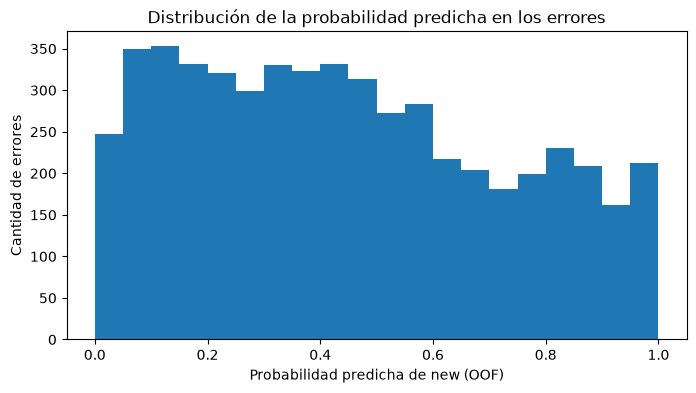

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(analisis.loc[analisis["error"] == 1, "prob_new"], bins=20, range=(0, 1))
ax.set_xlabel("Probabilidad predicha de new (OOF)")
ax.set_ylabel("Cantidad de errores")
ax.set_title("Distribución de la probabilidad predicha en los errores")
plt.show()

## 4. 60 errores para leer a mano

30 publicaciones `new` que el modelo predijo `used` y 30 `used` predichas `new`, elegidas **al azar** (`random_state=42`) para que sean representativas, no las más extremas.

In [14]:
columnas_a_mostrar = ["title", "warranty", "price", "listing_type_id", "seller_n_listings", "prob_new"]
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 100)

new_predicho_used = analisis[(analisis["real_new"] == 1) & (analisis["pred_new"] == 0)]
new_predicho_used.sample(30, random_state=SEED)[columnas_a_mostrar].sort_values("prob_new")

,title,warranty,price,listing_type_id,seller_n_listings,prob_new
31120,Sillon Antiguo Luis Xv,NaN,1900.0,free,1,0.012426
4294,El Cuento Una Pasión Argentina Cortazar Walsh Otros Q1,NaN,44.0,bronze,83,0.014452
3363,Estevez Vida De Un Cruzado. Federico Gaston Addisi. Malvinas,TODOS NUESTROS ARTICULOS ESTAN GARANTIZADOS POR NUESTRO PROFESIONALISMO Y NU...,120.0,bronze,120,0.052886
37835,Eric Hobsbawm. Guerra Y Paz En El Siglo Xxi,NaN,39.0,bronze,10,0.070000
25781,Departamento A Estrenar Con Balcon A La Calle 2 Ambientes.,NaN,65000.0,free,1,0.075288
22659,Garra De Peluches,NaN,1800.0,bronze,2,0.118763
9539,Espectacular!! Remera Origi. National Guard- Citizen Soldier,Sin garantía,270.0,silver,7,0.136845
14462,Bajo Ibanez Gio Gsr 205 -5 Strings-,NaN,7300.0,bronze,2,0.153686
8882,Muñeco Quake 2 Athena Jungle Marine,mi reputacion,500.0,bronze,31,0.155545
39450,Hermosa Zapatilla De Nena - Talle 19 Con Abrojos,NaN,100.0,bronze,2,0.159319


In [15]:
used_predicho_new = analisis[(analisis["real_new"] == 0) & (analisis["pred_new"] == 1)]
used_predicho_new.sample(30, random_state=SEED)[columnas_a_mostrar].sort_values("prob_new")

,title,warranty,price,listing_type_id,seller_n_listings,prob_new
67754,Funda Pistolera De Cuero Con Portacargador,NaN,250.00,bronze,1,0.501759
35469,Gps Garmin De Mano,NaN,2000.00,free,1,0.510318
3574,Vestido / Camisola Importado,NaN,110.00,bronze,8,0.511958
38556,Libro Estrategias Para El Liderazgo Competitivo - Hax Majluf,NaN,250.00,bronze,1,0.519716
33721,Chacra 12 Ha Sin Mejoras Marcos Paz,NaN,90000.00,silver,1,0.520324
4850,Steady Cam Tipo Merlin,NaN,2900.00,bronze,1,0.534013
20804,Cartas Mazo De Naipes Kem Sin Uso Lavables (importadas),NaN,650.00,bronze,1,0.548869
15963,Clio 2 Campus 1.2 3p 2012 Nuevo! ! !,NaN,107100.00,gold,1,0.557138
66288,Practicuna Kiddy Casi Nueva,NaN,900.00,free,1,0.573066
54491,Anteojos De Sol,NaN,200.00,silver,1,0.589987


### Palabras clave en el título y en la garantía

Leyendo los errores aparecen dos patrones: títulos que dicen "nuevo" / "sin uso" pero son `used`, y textos de `warranty` que parecen muy informativos ("garantía de fábrica" vs "mi reputación"). Hoy el modelo usa el título con TF-IDF de 500 palabras sueltas y de `warranty` solo la flag `tiene_garantia` (si es nula o no), **no el texto**. Chequeo con expresiones regulares simples qué tan separadas están las clases en esos grupos.

In [16]:
titulo = analisis["title"].str.lower()
garantia = analisis["warranty"].fillna("").str.lower()

grupos_texto = {
    "título dice nuevo/a": titulo.str.contains(r"\bnuev"),
    "título dice usado/a": titulo.str.contains(r"\busad"),
    "título dice sin uso / impecable / casi nuevo / excelente estado":
        titulo.str.contains(r"sin uso|impecable|casi nuev|excelente estado|muy buen estado"),
    "título dice antiguo / vintage / colección / retro": titulo.str.contains(r"antig|vintage|colecci|retro"),
    "warranty nula": garantia.eq(""),
    "warranty con texto": garantia.ne(""),
    "warranty dice sin garantía": garantia.str.contains(r"sin garant"),
    "warranty dice nuevo / fábrica / oficial": garantia.str.contains(r"nuev|fábrica|fabrica|oficial"),
    "warranty dice usado / reputación / personal": garantia.str.contains(r"usad|reputaci|personal"),
}

filas = []
for nombre, mascara in grupos_texto.items():
    grupo = analisis[mascara]
    filas.append({
        "grupo": nombre,
        "n": len(grupo),
        "pct_del_total": len(grupo) / len(analisis),
        "pct_new_real": grupo["real_new"].mean(),
        "accuracy": 1 - grupo["error"].mean(),
        "n_errores": grupo["error"].sum(),
    })
pd.DataFrame(filas).set_index("grupo").round(3)

,n,pct_del_total,pct_new_real,accuracy,n_errores
grupo,,,,,
título dice nuevo/a,3276,0.047,0.804,0.919,265
título dice usado/a,601,0.009,0.017,0.942,35
título dice sin uso / impecable / casi nuevo / excelente estado,1147,0.016,0.086,0.934,76
título dice antiguo / vintage / colección / retro,2872,0.041,0.188,0.924,217
warranty nula,42658,0.609,0.484,0.906,4026
warranty con texto,27342,0.391,0.620,0.951,1344
warranty dice sin garantía,3814,0.054,0.347,0.931,264
warranty dice nuevo / fábrica / oficial,4514,0.064,0.979,0.977,102
warranty dice usado / reputación / personal,1229,0.018,0.321,0.935,80


## 5. Conclusión

**Chequeo de la Base.** Da 0,9233 ± 0,0010 de accuracy y 0,9783 de roc_auc. Es exactamente el bloque K de `07_nuevas_features.ipynb` (0,9184 + 0,0049). El 0,9237 de la referencia anterior es el Gradient Boosting tuneado de `train.ipynb` (otros hiperparámetros); la diferencia (0,0004) es menos de la mitad del desvío entre folds. **Base reproducida.** Errores: 5.370 de 70.000, más `new` predichas `used` (3.201) que al revés (2.169).

**Lo confirmado por los números:**

1. **Los errores se concentran en los vendedores con 1 sola publicación.** Son el 28,5% de las filas pero el **54% de los errores** (accuracy 0,854, contra 0,93–0,98 en el resto). Tiene sentido: para ellos `VendedorEncoder` no aporta nada (`seller_pct_new` cae al promedio global) y el modelo depende solo del contenido de la publicación.
2. **Los otros segmentos casi no discriminan.** `listing_type_id`, rango de precio y las 15 categorías principales tienen accuracy parecida al promedio (0,92 ± 0,01). USD (0,81), `classified` (0,88) y `auction` (0,88) son peores pero suman < 5% de los errores, y no conviene dedicarles un paso. Ninguna categoría concentra errores: las 15 principales son el 13% de las filas y el 11% de los errores.
3. **La mayoría de los errores son "dudosos".** El 42% tiene confianza < 0,7 y otro 40% está entre 0,7 y 0,9. Solo el 18% (971 errores, el 1,4% de las filas) son errores "seguros", con confianza > 0,9.
4. **El texto de `warranty` separa mucho y hoy no se usa.** Cuando dice "fábrica / oficial / nuevo", el 98% es `new`; cuando dice "reputación / personal / usado", solo el 32%. El modelo solo ve si es nula o no. Ojo: en ese grupo el modelo ya acierta el 97,7%, así que buena parte de esa señal ya le llega por otro lado (tienda oficial, vendedor). La ganancia esperable de T3 es moderada, no proporcional a esa separación. Además, las publicaciones **sin** `warranty` (61%) son las más difíciles (0,906), y ahí este texto no puede ayudar.

**Lectura de los 60 errores (interpretación mía, no medida):**

- **Ruido o ambigüedad irreducible**, sobre todo en los errores seguros:
  - Etiqueta que contradice el título: "Clio 2 … 2012 Nuevo!!!", "Crysis 2 Ps3 Nuevo", "Cartas … Sin Uso" etiquetadas `used`.
  - Un caso discutible etiquetado `new`: "Sillon Antiguo Luis Xv" (un sillón antiguo difícilmente sea "nuevo"; el vendedor probablemente quiso decir "en excelente estado").
  - *Corrección posterior:* "Departamento A Estrenar" (a estrenar = nuevo), estampillas "Mint" (en filatelia, sin usar) y los libros etiquetados `new` **no** son ruido de etiqueta: la etiqueta es razonable y el error es del **modelo** (por ejemplo, un inmueble en publicación gratuita de un vendedor con 1 sola publicación se parece al perfil de un particular).
  - En un auto, un inmueble o una antigüedad, la condición la decide el vendedor con criterio propio. Estimación gruesa del techo: si casi todos los errores seguros fueran ruido, el máximo alcanzable rondaría 0,985. En la práctica es bastante menos, porque muchos dudosos también son ambiguos. **No es medible con estos datos.**
- **Patrones que el modelo podría capturar:**
  - Frases de varias palabras: "casi nueva", "sin uso", "nuevos y usados". El TF-IDF actual solo ve palabras sueltas, sin bigramas, y tiene "nuevo" y "uso" por separado.
  - Errores de tipeo y abreviaturas ("Origi.", "C/lycra", "Gtia"), que los n-gramas de caracteres pueden absorber.
  - El texto de la garantía.
  - Para los vendedores de 1 publicación, cualquier información extra de contenido (fotos, atributos).

**Orden recomendado para los pasos 2 a 4: Paso 2 → Paso 4 → Paso 3.**

1. **Paso 2 (texto) primero.** Ataca directo el problema principal: los vendedores sin historial dependen del contenido, y ahí lo más rico es el título (bigramas, caracteres) y el texto de `warranty` (T3), que mostró una separación fuerte y hoy se desperdicia.
2. **Paso 4 (anidadas) segundo.** Fotos, atributos y variaciones son más contenido de la publicación, o sea, señal que también existe para los vendedores de 1 publicación.
3. **Paso 3 (vendedor v2) último.** V1 (`TargetEncoder` en vez de *leave-one-out*) no cambia nada para los vendedores de 1 publicación (en los dos casos caen al promedio global), que es donde está más de la mitad de los errores. Solo puede mejorar los de 2–5 (21% de los errores). V2 (contar con train + test) sí puede ayudar a algunos "1 en train", pero solo agrega cantidad, no `pct_new`. Es un paso barato, así que el orden importa poco, pero el potencial esperado es menor.